# Module 8 — Task 1: Black-Scholes benchmark

**The business question (brief, verbatim):**
> NovaFin has exposure to equity options. Management wants to know: **Can ML improve option pricing and help manage derivatives exposure?**

**Task 1 (brief, verbatim):**
> **Task 1 — Black-Scholes benchmark.** Calculate theoretical option price. Compare: BS Price with: Market Price

**In plain words:** work out each option's fair price with the standard formula (Black-Scholes), see how close it is to the price the market actually pays, find where it misses, and measure the risk the option book carries. Task 2 then asks whether ML can price better.

**Terms used throughout**

| Term | What it is, simply | Example |
| --- | --- | --- |
| **Option** | A contract giving the **right, not the duty**, to buy or sell a stock at a fixed price by a fixed date. The buyer pays a price for this right | Pay ₹100 today for the right to buy Reliance at ₹1,500 within 6 months |
| **Call** | The right to **buy** at a fixed price; gains when the stock **rises** | Right to buy at ₹1,500; stock at ₹1,700 → worth ₹200 |
| **Put** | The right to **sell** at a fixed price; gains when the stock **falls** (often used as insurance) | Right to sell at ₹1,500; stock at ₹1,300 → worth ₹200 |
| **Strike** | The fixed price written in the option | ₹1,500 |
| **Spot** | The stock's price today | ₹1,450 |
| **Time to maturity** | Time left until the option ends, in years | 6 months = 0.5 |
| **Volatility** | How much the stock swings in a year; bigger swings make options worth more | 25% a year |
| **Interest rate** | Return on safe money; affects today's value of a price paid later | 7% a year |
| **In / at / out of the money** | Would using the option today pay? A call is in the money when spot > strike, a put when spot < strike | Spot ₹1,700, strike ₹1,500: the call is 13% in the money |
| **Black-Scholes (BS)** | The standard formula for an option's fair price from 5 inputs (spot, strike, time, volatility, rate). It averages the payoff over all the ways the stock could move | Spot 1,500, strike 1,550, 0.5 yr, 25%, 7% → call ₹107.20 |
| **Market price** | What the option actually trades for | ₹110 |
| **Gap** | Market price − BS price | ₹110 − ₹107.20 = +₹2.80 |
| **MAE / RMSE / bias** | Average size of the gap / typical gap with big misses counted extra / average signed gap (is BS too low or too high?) | Gaps +2, −4 → MAE 3, RMSE 3.2, bias −1 |
| **No-arbitrage floor** | The lowest price an option can logically have; below it, buying it would be free money | Call floor = spot − today's value of the strike |
| **Greeks** | How much the option price moves when one input moves (delta: stock ₹1; gamma: how fast delta changes; vega: volatility +1 point; theta: one day passing) | Delta 0.6 → stock +₹1, option +₹0.60 |

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Know the data |
| 2 | Explore the data (EDA): what options are in the book; data check: one price per stock? (M8-18) |
| 3 | Calculate the Black-Scholes price and check it (M8-01) |
| 4 | How close is BS to the market? In ₹ and % (M8-06) |
| 5 | Where does BS miss? Breakdowns with tests (M8-07) |
| 6 | Impossible market prices (M8-08) |
| 7 | Greeks: the risk in the option book, in ₹, including volatility (M8-04, M8-05, M8-19) |
| 8 | What Task 1 means for Task 2 (review) |
| 9 | What the results say |
| 10 | Save the outputs |

## 0. Setup
Works locally and in Google Colab. Runs in about 1 minute.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")        # stops a harmless Windows warning
# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_08_derivatives"
OUT_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score
import lightgbm as lgb

from m08_data import load_options, data_report
from m08_black_scholes import bs_price, greeks, price_frame
from m08_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42                                   # project rule P-06: every random step uses 42
rng = np.random.default_rng(SEED)
MIN_PRICE_FOR_PCT = 1.0                     # M8-06: % gaps only for options worth ₹1 or more
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    """Save a table as CSV in outputs/task1."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    """Save a chart as PNG in outputs/task1 and show it."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()

## 1. Know the data
`nova_options.csv`: one row per option. Checks: size, gaps, calls vs puts, stocks, ranges, and the pricing date (expiry − time to maturity).

In [2]:
df = load_options()
for k, v in data_report(df).items():
    print(f"{k:35s} {v}")
pricing_date = (df.Expiry - pd.to_timedelta(df.Time_to_Maturity * 365.25, unit="D")).dt.normalize()
print("Pricing date implied by expiry − time to maturity:", pricing_date.min().date(), "to", pricing_date.max().date(),
      "→ every option is priced on the same day")
df["Is call"] = df.Option_Type == "Call"
# How far in the money: + = would pay if used today, − = would not (as a share of the strike)
df["In the money by"] = np.where(df["Is call"], df.Spot / df.Strike - 1, df.Strike / df.Spot - 1)
df.head(3)

rows                                10000
missing_values                      0
option_types                        {'Put': 5055, 'Call': 4945}
underlyings                         15
maturity_years_range                (0.03, 2.0)
volatility_range                    (0.08, 0.536)
non_positive_prices                 0
mean_abs_gap_market_vs_given_BS     5.84
Pricing date implied by expiry − time to maturity: 2026-08-31 to 2026-09-01 → every option is priced on the same day


,Option_ID,Underlying,Option_Type,Strike,Spot,Expiry,Time_to_Maturity,Volatility,Interest_Rate,Black_Scholes_Price,Market_Price,Is call,In the money by
0,7000001,MARUTI,Put,2235.17,1863.14,2027-04-18,0.6273,0.1954,0.0743,302.60,320.43,False,0.199679
1,7000002,KOTAKBANK,Call,1187.03,1544.48,2028-01-24,1.3967,0.2891,0.0733,504.59,494.33,True,0.301130
2,7000003,RELIANCE,Call,896.16,1048.48,2027-12-28,1.3207,0.4265,0.0591,311.49,305.30,True,0.169970


## 2. Explore the data (EDA): what options are in the book
What kinds of options NovaFin holds: calls vs puts, how far in or out of the money, how long they run, how volatile the stocks are, and how prices are spread. This tells us which parts of the book matter most in ₹ and whether any group is too small to judge.

In [3]:
def band_money(x):
    """Plain moneyness band from 'in the money by' (share of strike)."""
    return pd.cut(x, [-np.inf, -0.10, -0.02, 0.02, 0.10, np.inf],
                  labels=["Far out of the money (< −10%)", "Out of the money (−10% to −2%)", "At the money (±2%)",
                          "In the money (2% to 10%)", "Far in the money (> 10%)"])


df["Moneyness band"] = band_money(df["In the money by"])
df["Maturity band"] = pd.cut(df.Time_to_Maturity, [0, 0.25, 0.5, 1.0, 2.01],
                             labels=["Under 3 months", "3–6 months", "6–12 months", "1–2 years"])
df["Volatility band"] = pd.cut(df.Volatility, [0, 0.15, 0.20, 0.25, 0.30, 1],
                               labels=["Under 15%", "15–20%", "20–25%", "25–30%", "Over 30%"])

describe = df[["Spot", "Strike", "In the money by", "Time_to_Maturity", "Volatility", "Interest_Rate", "Market_Price"]].describe(
    percentiles=[0.05, 0.5, 0.95]).T[["min", "5%", "50%", "95%", "max"]].round(3)
describe.index = ["Spot (₹)", "Strike (₹)", "In the money by (share)", "Time to maturity (years)", "Volatility (a year)",
                  "Interest rate (a year)", "Market price (₹)"]
print("Ranges of each input:"); display(describe)

eda_groups = []
for col in ["Option_Type", "Moneyness band", "Maturity band", "Volatility band"]:
    g = df.groupby(col, observed=True).agg(Options=("Option_ID", "size"), **{"Average market price (₹)": ("Market_Price", "mean"),
                                           "Total market value (₹ lakh, one unit each)": ("Market_Price", lambda s: s.sum() / 1e5)})
    g.insert(0, "Breakdown", col.replace("_", " ")); eda_groups.append(g.reset_index().rename(columns={col: "Group"}))
eda_groups = pd.concat(eda_groups, ignore_index=True)
eda_groups["Share of options"] = eda_groups.Options / len(df)
print("What the book holds:"); display(eda_groups.round(2))

by_stock_eda = df.groupby("Underlying").agg(Options=("Option_ID", "size"), Calls=("Is call", "sum"),
                                            **{"Typical spot (₹)": ("Spot", "median"), "Typical volatility": ("Volatility", "median"),
                                               "Total market value (₹ lakh)": ("Market_Price", lambda s: s.sum() / 1e5)}).round(2)
print("By stock:"); display(by_stock_eda)
# Data check (decision M8-18): on one pricing day a real stock has ONE price and one volatility. Does each stock here?
spot_check = df.groupby("Underlying").agg(**{"Options": ("Option_ID", "size"), "Different spot prices": ("Spot", "nunique"),
    "Lowest spot (₹)": ("Spot", "min"), "Highest spot (₹)": ("Spot", "max"), "Different volatilities": ("Volatility", "nunique"),
    "Lowest volatility": ("Volatility", "min"), "Highest volatility": ("Volatility", "max")})
print("Spot price and volatility within each stock (one pricing day):"); display(spot_check.head(5).round(3))
SPOTS_PER_STOCK = int(spot_check["Different spot prices"].min())
print(f"Every stock has {SPOTS_PER_STOCK}+ different spot prices (₹{df.Spot.min():,.0f}–₹{df.Spot.max():,.0f}) and its own volatility per option. "
      "In a real market one stock has one price on a day, so the stock label does not tie options together the way a real stock would. "
      "What this means: BS pricing is unaffected (it uses each row's own inputs); risk and hedges are added up in ₹ per option, "
      "and share counts per stock are not meaningful.")
corr = df[["Spot", "Strike", "In the money by", "Time_to_Maturity", "Volatility", "Interest_Rate"]].corr(method="spearman").round(2)
print("Links between inputs (rank correlation, −1 to +1; near 0 = unrelated):"); display(corr)

Ranges of each input:


,min,5%,50%,95%,max
Spot (₹),100.590,267.222,1787.605,3328.286,3499.600
Strike (₹),78.350,256.355,1753.065,3514.525,4348.870
In the money by (share),-0.250,-0.202,-0.005,0.247,0.333
Time to maturity (years),0.030,0.127,1.000,1.905,2.000
Volatility (a year),0.080,0.109,0.239,0.370,0.536
Interest rate (a year),0.034,0.052,0.065,0.078,0.099
Market price (₹),0.010,2.249,123.620,617.259,1245.560


What the book holds:


,Group,Breakdown,Options,Average market price (₹),"Total market value (₹ lakh, one unit each)",Share of options
0,Call,Option Type,4945,248.36,12.28,0.49
1,Put,Option Type,5055,140.73,7.11,0.51
2,Far out of the money (< −10%),Moneyness band,2931,66.51,1.95,0.29
3,Out of the money (−10% to −2%),Moneyness band,1740,117.81,2.05,0.17
4,At the money (±2%),Moneyness band,832,169.30,1.41,0.08
5,In the money (2% to 10%),Moneyness band,1495,214.89,3.21,0.15
6,Far in the money (> 10%),Moneyness band,3002,358.93,10.78,0.30
7,Under 3 months,Maturity band,1154,118.26,1.36,0.12
8,3–6 months,Maturity band,1198,146.23,1.75,0.12
9,6–12 months,Maturity band,2647,176.92,4.68,0.26


By stock:


,Options,Calls,Typical spot (₹),Typical volatility,Total market value (₹ lakh)
Underlying,,,,,
AXISBANK,657,333,1812.63,0.24,1.29
BHARTIARTL,665,328,1709.03,0.24,1.24
HDFCBANK,668,357,1804.74,0.25,1.35
HINDUNILVR,695,332,1821.93,0.25,1.40
ICICIBANK,698,336,1806.24,0.23,1.33
INFY,702,354,1855.80,0.24,1.36
ITC,643,325,1904.38,0.23,1.28
KOTAKBANK,676,313,1771.28,0.24,1.29
LT,639,326,1844.29,0.24,1.26


Spot price and volatility within each stock (one pricing day):


,Options,Different spot prices,Lowest spot (₹),Highest spot (₹),Different volatilities,Lowest volatility,Highest volatility
Underlying,,,,,,,
AXISBANK,657,656,101.83,3489.98,569,0.08,0.472
BHARTIARTL,665,665,105.52,3495.74,573,0.08,0.468
HDFCBANK,668,667,102.49,3498.52,586,0.08,0.492
HINDUNILVR,695,695,103.74,3496.55,614,0.08,0.536
ICICIBANK,698,697,100.59,3499.54,586,0.08,0.478


Every stock has 623+ different spot prices (₹101–₹3,500) and its own volatility per option. In a real market one stock has one price on a day, so the stock label does not tie options together the way a real stock would. What this means: BS pricing is unaffected (it uses each row's own inputs); risk and hedges are added up in ₹ per option, and share counts per stock are not meaningful.
Links between inputs (rank correlation, −1 to +1; near 0 = unrelated):


,Spot,Strike,In the money by,Time_to_Maturity,Volatility,Interest_Rate
Spot,1.00,0.97,-0.01,0.01,-0.00,-0.01
Strike,0.97,1.00,-0.00,0.01,0.00,-0.01
In the money by,-0.01,-0.00,1.00,0.00,0.02,-0.00
Time_to_Maturity,0.01,0.01,0.00,1.00,-0.01,0.02
Volatility,-0.00,0.00,0.02,-0.01,1.00,-0.01
Interest_Rate,-0.01,-0.01,-0.00,0.02,-0.01,1.00


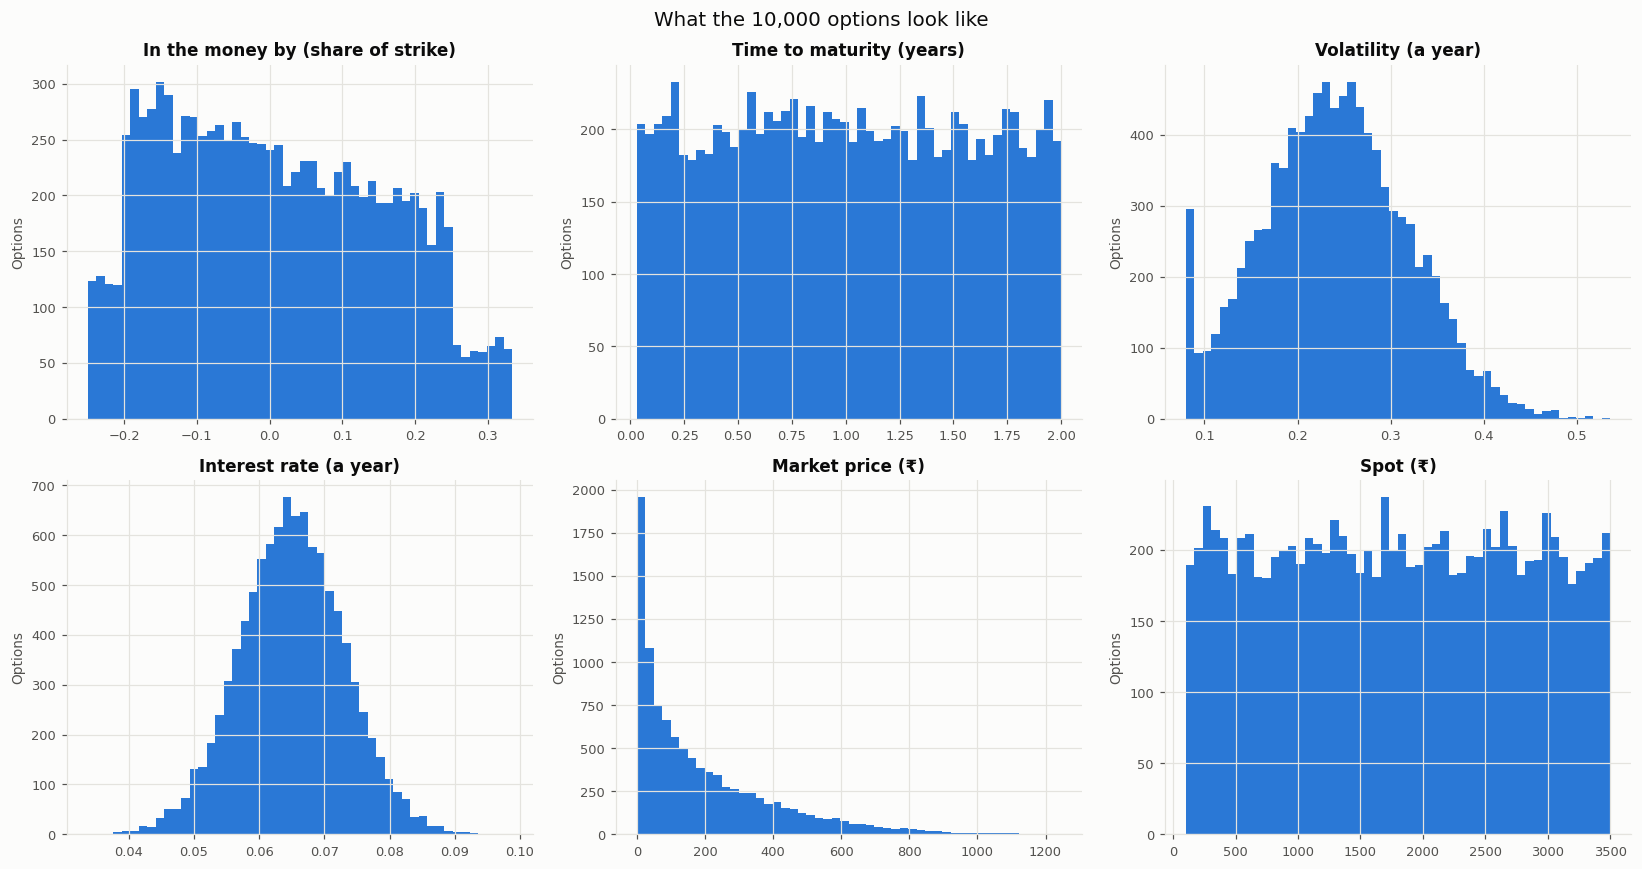

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, (c, lab) in zip(ax.flat, [("In the money by", "In the money by (share of strike)"), ("Time_to_Maturity", "Time to maturity (years)"),
                                 ("Volatility", "Volatility (a year)"), ("Interest_Rate", "Interest rate (a year)"),
                                 ("Market_Price", "Market price (₹)"), ("Spot", "Spot (₹)")]):
    a.hist(df[c], bins=50, color=BLUE)
    a.set_title(lab); a.set_ylabel("Options")
fig.suptitle("What the 10,000 options look like", fontsize=13)
fig.tight_layout()
save_chart(fig, "01_eda_inputs")

## 3. Calculate the Black-Scholes price and check it (decision M8-01)
For each option, from its own spot, strike, time, volatility and rate (no dividends):
```text
d1 = [ln(spot ÷ strike) + (rate + volatility² ÷ 2) × time] ÷ (volatility × √time)
d2 = d1 − volatility × √time
Call = spot × N(d1) − strike × e^(−rate × time) × N(d2)
Put  = strike × e^(−rate × time) × N(−d2) − spot × N(−d1)
N(x) = the chance a standard bell-curve value is below x (0 to 1);  e^(−rate × time) = today's value of ₹1 paid at the end
```
**In words:** a call is worth "the stock you'd likely get" minus "today's value of the strike you'd likely pay"; N(d1) and N(d2) are the likelihoods. We check our price against the file's `Black_Scholes_Price`.

In [5]:
df["BS price"] = price_frame(df)
diff = (df["BS price"] - df.Black_Scholes_Price).abs()
print(f"Our BS vs the file's BS: largest difference ₹{diff.max():.2f}, average ₹{diff.mean():.3f}, "
      f"{(diff <= 0.01).mean():.1%} within 1 paisa → the formula matches (differences are rounding)")
ex = float(bs_price(1500, 1550, 0.5, 0.25, 0.07, True))
print(f"Worked example: spot ₹1,500, strike ₹1,550, 0.5 years, volatility 25%, rate 7%, call → ₹{ex:.2f}")
r = df.iloc[0]
print(f"First option in the file: {r.Underlying} {r.Option_Type}, strike ₹{r.Strike:,.2f}, spot ₹{r.Spot:,.2f}, "
      f"{r.Time_to_Maturity:.2f} years, volatility {r.Volatility:.1%}, rate {r.Interest_Rate:.2%} → our BS ₹{r['BS price']:.2f} "
      f"(file ₹{r.Black_Scholes_Price:.2f}); market ₹{r.Market_Price:.2f}")

Our BS vs the file's BS: largest difference ₹0.27, average ₹0.025, 43.5% within 1 paisa → the formula matches (differences are rounding)
Worked example: spot ₹1,500, strike ₹1,550, 0.5 years, volatility 25%, rate 7%, call → ₹107.20
First option in the file: MARUTI Put, strike ₹2,235.17, spot ₹1,863.14, 0.63 years, volatility 19.5%, rate 7.43% → our BS ₹302.61 (file ₹302.60); market ₹320.43


## 4. How close is BS to the market? (decision M8-06)
**Gap = market price − BS price.** Measured in ₹ (what NovaFin would gain or lose per option) for every option, and in % of the BS price only for options worth ₹1 or more (on a 10-paise option, a 5-paise gap would read as 50%).
- **MAE** = average |gap|; **RMSE** = √(average gap²), which counts big misses extra; **bias** = average gap (+ = market above BS).
- 95% ranges from resampling the options 1,000 times (seed 42).

In [6]:
df["Gap (₹)"] = df.Market_Price - df["BS price"]
big = df["BS price"] >= MIN_PRICE_FOR_PCT
df["Gap (% of BS)"] = np.where(big, df["Gap (₹)"] / df["BS price"], np.nan)


def gap_stats(g: pd.Series) -> dict:
    """MAE, RMSE and bias of a set of gaps (₹)."""
    return {"MAE (₹)": g.abs().mean(), "RMSE (₹)": np.sqrt((g ** 2).mean()), "Bias (₹)": g.mean()}


def boot_range(g: np.ndarray, n: int = 1000) -> dict:
    """95% range of MAE, RMSE and bias from resampling the options (seed 42)."""
    r = np.random.default_rng(SEED)
    sims = [gap_stats(pd.Series(g[r.integers(0, len(g), len(g))])) for _ in range(n)]
    s = pd.DataFrame(sims)
    return {k: (s[k].quantile(0.025), s[k].quantile(0.975)) for k in s}


G = gap_stats(df["Gap (₹)"]); B = boot_range(df["Gap (₹)"].to_numpy())
pct = df.loc[big, "Gap (% of BS)"]
headline = pd.DataFrame([
    ["Average gap size (MAE)", f"₹{G['MAE (₹)']:.2f}", f"₹{B['MAE (₹)'][0]:.2f} to ₹{B['MAE (₹)'][1]:.2f}", "How far BS is from the market, on average, per option"],
    ["Typical gap, big misses counted extra (RMSE)", f"₹{G['RMSE (₹)']:.2f}", f"₹{B['RMSE (₹)'][0]:.2f} to ₹{B['RMSE (₹)'][1]:.2f}", "Higher than MAE → some large misses"],
    ["Bias (average market − BS)", f"₹{G['Bias (₹)']:+.2f}", f"₹{B['Bias (₹)'][0]:+.2f} to ₹{B['Bias (₹)'][1]:+.2f}", "Range includes 0 → BS is not too high or too low on average"],
    ["Typical gap as % of BS (median |gap|, options ≥ ₹1)", f"{pct.abs().median():.2%}", "—", "Half the options are closer than this"],
    ["Options within ±5% of BS (≥ ₹1)", f"{(pct.abs() <= 0.05).mean():.0%}", "—", "Share close enough for everyday use"],
    ["Options more than 20% from BS (≥ ₹1)", f"{(pct.abs() > 0.20).mean():.1%}", "—", "Large misses, mostly cheap options"],
    ["Total |gap| as share of book value (one unit each)", f"{df['Gap (₹)'].abs().sum() / df.Market_Price.sum():.2%}",
     "—", f"≈ ₹{df['Gap (₹)'].abs().sum() / df.Market_Price.sum() * 100:.1f} lakh per ₹1 crore of options, if each were valued at BS instead of market"],
], columns=["Measure", "Value", "95% range", "Meaning"])
display(headline)

df["Price fifth"] = pd.qcut(df["BS price"], 5, labels=["1 (cheapest)", "2", "3", "4", "5 (dearest)"])
by_price = df.groupby("Price fifth", observed=True).agg(**{"BS price from (₹)": ("BS price", "min"), "to (₹)": ("BS price", "max"),
    "MAE (₹)": ("Gap (₹)", lambda g: g.abs().mean()), "Bias (₹)": ("Gap (₹)", "mean"),
    "Median |gap| (% of BS)": ("Gap (% of BS)", lambda g: g.abs().median())}).round(4)
print("Gap by price (fifths of BS price):"); display(by_price)
print(f"Shape of the gap: skew {stats.skew(df['Gap (₹)']):+.2f} (0 = symmetric), extra tail weight (kurtosis) "
      f"{stats.kurtosis(df['Gap (₹)']):.1f} (0 = bell curve) → mostly small, a few large")

,Measure,Value,95% range,Meaning
0,Average gap size (MAE),₹5.84,₹5.69 to ₹6.01,"How far BS is from the market, on average, per..."
1,"Typical gap, big misses counted extra (RMSE)",₹9.81,₹9.51 to ₹10.14,Higher than MAE → some large misses
2,Bias (average market − BS),₹+0.05,₹-0.14 to ₹+0.25,Range includes 0 → BS is not too high or too l...
3,"Typical gap as % of BS (median |gap|, options ...",3.14%,—,Half the options are closer than this
4,Options within ±5% of BS (≥ ₹1),69%,—,Share close enough for everyday use
5,Options more than 20% from BS (≥ ₹1),6.1%,—,"Large misses, mostly cheap options"
6,Total |gap| as share of book value (one unit e...,3.01%,—,"≈ ₹3.0 lakh per ₹1 crore of options, if each w..."


Gap by price (fifths of BS price):


,BS price from (₹),to (₹),MAE (₹),Bias (₹),Median |gap| (% of BS)
Price fifth,,,,,
1 (cheapest),0.0000,25.8273,1.4800,0.1533,0.1287
2,25.8376,81.9635,2.1143,-0.0442,0.0351
3,81.9960,177.0380,3.9147,0.0043,0.0270
4,177.1223,342.8446,7.2773,0.0422,0.0248
5 (dearest),342.9813,1188.4225,14.4238,0.1091,0.0232


Shape of the gap: skew +0.26 (0 = symmetric), extra tail weight (kurtosis) 9.7 (0 = bell curve) → mostly small, a few large


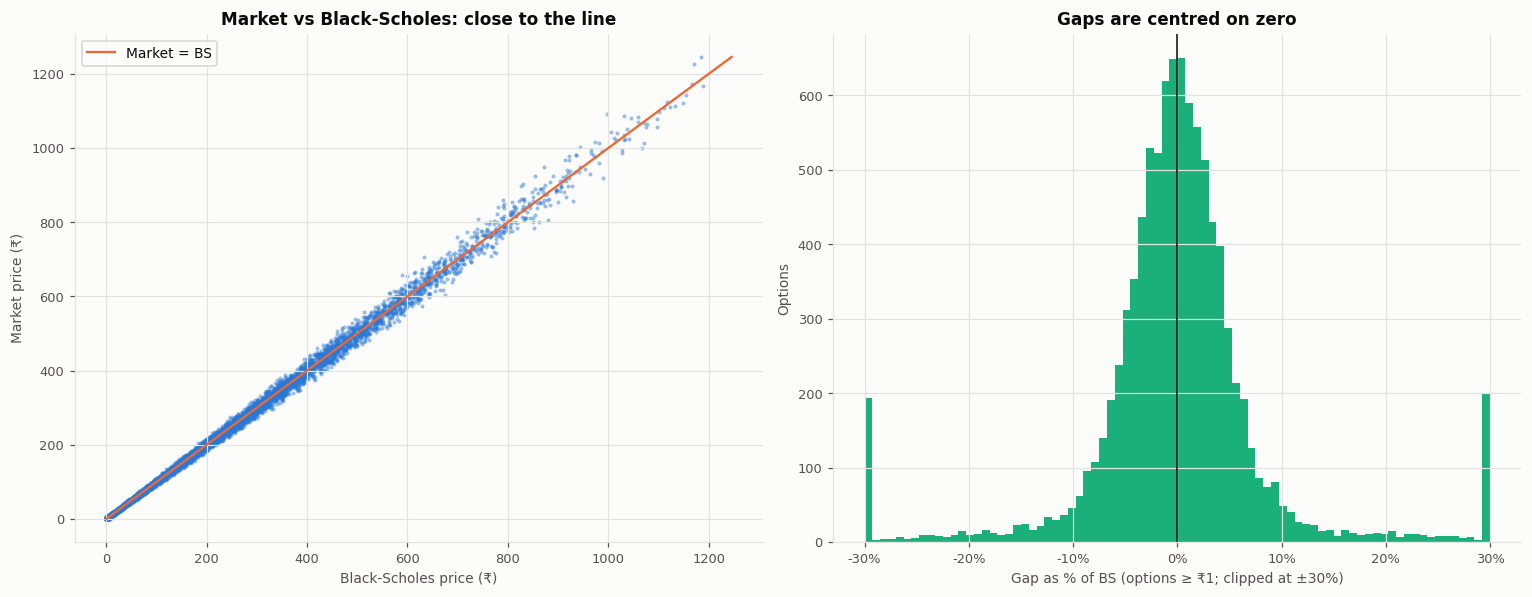

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(df["BS price"], df.Market_Price, s=3, alpha=0.35, color=BLUE)
m = df.Market_Price.max(); ax[0].plot([0, m], [0, m], color=ORANGE, lw=1.5, label="Market = BS")
ax[0].set_xlabel("Black-Scholes price (₹)"); ax[0].set_ylabel("Market price (₹)"); ax[0].legend()
ax[0].set_title("Market vs Black-Scholes: close to the line")
ax[1].hist(pct.clip(-0.3, 0.3), bins=80, color=AQUA)
ax[1].axvline(0, color=INK, lw=1); ax[1].set_xlabel("Gap as % of BS (options ≥ ₹1; clipped at ±30%)"); ax[1].set_ylabel("Options")
ax[1].set_title("Gaps are centred on zero")
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
save_chart(fig, "02_market_vs_bs")

## 5. Where does BS miss? (decision M8-07)
If BS misses in a **pattern** (e.g. always too cheap for far-out-of-the-money puts — the "volatility smile" seen in real markets), a model could learn it in Task 2. If the gap is **random**, nothing can learn it.
- For each breakdown: MAE, bias and median |gap %| by group.
- **Tests** (options ≥ ₹1, % gap so cheap and dear options compare fairly): does the **direction** of the gap differ between groups (Kruskal-Wallis on the signed % gap), and does its **size** differ (on |% gap|)? 6 breakdowns × 2 = 12 tests, so the line is 0.05 ÷ 12 ≈ 0.004 (Bonferroni: a stricter line because we run many tests).

In [8]:
BREAKDOWNS = {"Call or put": "Option_Type", "Moneyness": "Moneyness band", "Maturity": "Maturity band",
              "Volatility": "Volatility band", "Price fifth": "Price fifth", "Stock": "Underlying"}
LINE = 0.05 / (2 * len(BREAKDOWNS))
seg_rows, test_rows = [], []
for name, col in BREAKDOWNS.items():
    for grp, x in df.groupby(col, observed=True):
        xp = x.loc[x["BS price"] >= MIN_PRICE_FOR_PCT, "Gap (% of BS)"]
        seg_rows.append({"Breakdown": name, "Group": grp, "Options": len(x), "MAE (₹)": x["Gap (₹)"].abs().mean(),
                         "Bias (₹)": x["Gap (₹)"].mean(), "Median |gap| (% of BS)": xp.abs().median(),
                         "Average gap (% of BS)": xp.mean(), "Market above BS": (x["Gap (₹)"] > 0).mean()})
    sub = df[big]
    groups = [g["Gap (% of BS)"].to_numpy() for _, g in sub.groupby(col, observed=True)]
    p_dir = stats.kruskal(*groups).pvalue
    p_size = stats.kruskal(*[np.abs(g) for g in groups]).pvalue
    test_rows.append({"Breakdown": name, "Groups": len(groups), "p: direction differs": p_dir, "p: size differs": p_size,
                      "Passes the line (direction)": "Yes" if p_dir < LINE else "No",
                      "Passes the line (size)": "Yes" if p_size < LINE else "No"})
segments = pd.DataFrame(seg_rows); seg_tests = pd.DataFrame(test_rows)
print(f"Line for each test: {LINE:.4f}"); display(seg_tests.round(4))
display(segments.round(4))

links = pd.DataFrame([{"Input": c, "Rank link with gap %": stats.spearmanr(df.loc[big, c], pct).correlation,
                       "Rank link with |gap %|": stats.spearmanr(df.loc[big, c], pct.abs()).correlation}
                      for c in ["In the money by", "Time_to_Maturity", "Volatility", "Interest_Rate", "Spot", "Strike", "BS price"]])
print("Links between each input and the gap (−1 to +1; near 0 = no pattern):"); display(links.round(3))

Line for each test: 0.0042


,Breakdown,Groups,p: direction differs,p: size differs,Passes the line (direction),Passes the line (size)
0,Call or put,2,0.2362,0.0000,No,Yes
1,Moneyness,5,0.5673,0.0000,No,Yes
2,Maturity,4,0.1771,0.0000,No,Yes
3,Volatility,5,0.3158,0.0000,No,Yes
4,Price fifth,5,0.4914,0.0000,No,Yes
5,Stock,15,0.5159,0.4928,No,No


,Breakdown,Group,Options,MAE (₹),Bias (₹),Median |gap| (% of BS),Average gap (% of BS),Market above BS
0,Call or put,Call,4945,7.1864,-0.0856,0.0285,-0.0024,0.4918
1,Call or put,Put,5055,4.5269,0.1885,0.0349,0.0087,0.5092
2,Moneyness,Far out of the money (< −10%),2931,2.7224,0.1191,0.0453,0.0072,0.5125
3,Moneyness,Out of the money (−10% to −2%),1740,3.9700,-0.1280,0.0371,0.0057,0.4822
4,Moneyness,At the money (±2%),832,5.4207,-0.3165,0.0312,0.0028,0.4748
5,Moneyness,In the money (2% to 10%),1495,6.3953,0.0854,0.0275,-0.0011,0.5104
6,Moneyness,Far in the money (> 10%),3002,9.8142,0.1795,0.0243,0.0003,0.5020
7,Maturity,Under 3 months,1154,3.7922,-0.1005,0.0367,0.0092,0.5147
8,Maturity,3–6 months,1198,4.5096,-0.2634,0.0349,-0.0062,0.4766
9,Maturity,6–12 months,2647,5.2827,-0.0556,0.0317,0.0002,0.4998


Links between each input and the gap (−1 to +1; near 0 = no pattern):


,Input,Rank link with gap %,Rank link with |gap %|
0,In the money by,0.007,-0.275
1,Time_to_Maturity,0.017,-0.080
2,Volatility,0.003,-0.110
3,Interest_Rate,-0.003,0.012
4,Spot,0.005,-0.171
5,Strike,0.008,-0.187
6,BS price,0.014,-0.411


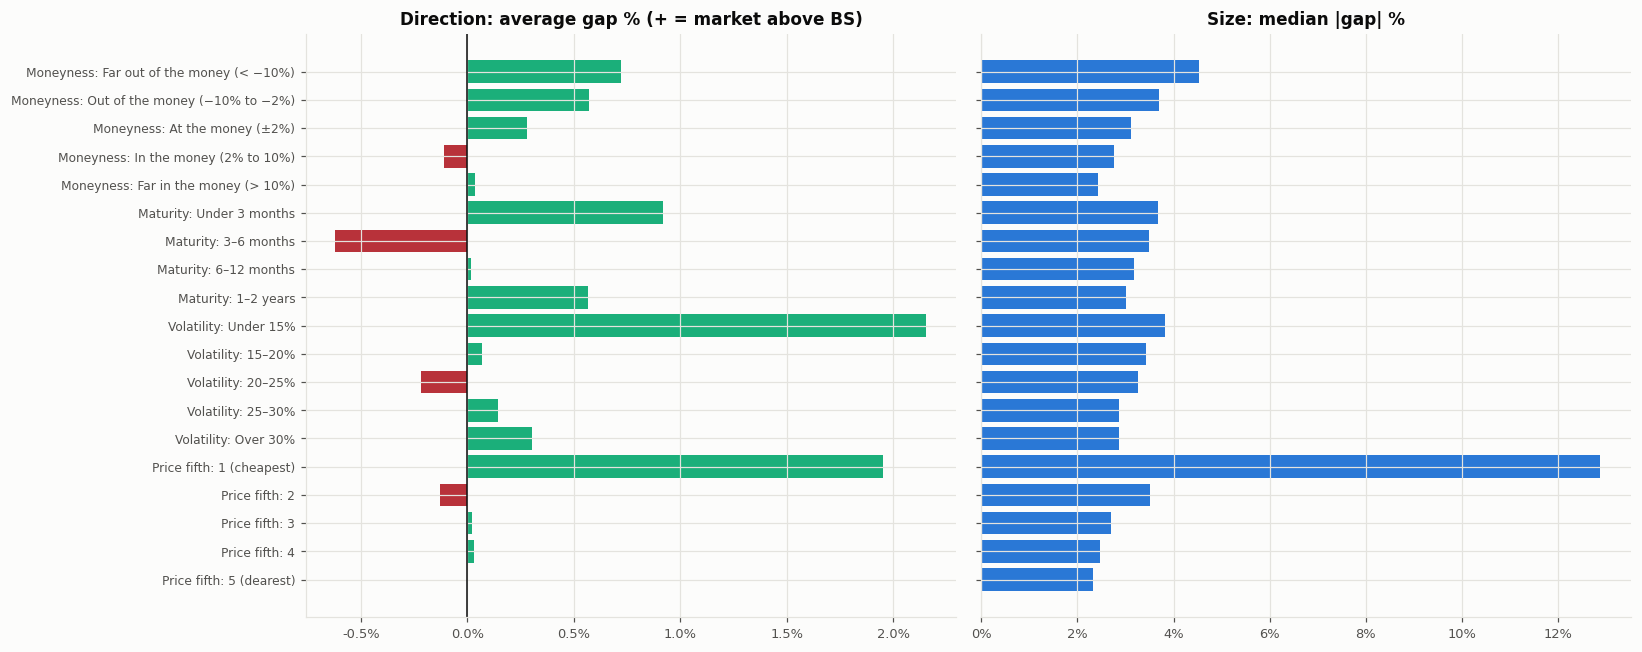

In [9]:
show = segments[segments.Breakdown.isin(["Moneyness", "Maturity", "Volatility", "Price fifth"])].copy()
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
lab = show.Breakdown + ": " + show.Group.astype(str)
y = np.arange(len(show))
ax[0].barh(y, show["Average gap (% of BS)"], color=[GAIN if v > 0 else LOSS for v in show["Average gap (% of BS)"]])
ax[0].set_yticks(y); ax[0].set_yticklabels(lab, fontsize=8); ax[0].axvline(0, color=INK, lw=1); ax[0].invert_yaxis()
ax[0].set_title("Direction: average gap % (+ = market above BS)"); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax[1].barh(y, show["Median |gap| (% of BS)"], color=BLUE)
ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].invert_yaxis()
ax[1].set_title("Size: median |gap| %"); ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
save_chart(fig, "03_where_bs_misses")

## 6. Impossible market prices (decision M8-08)
An option can't logically cost less than its **no-arbitrage floor**:
```text
Call floor = max(spot − strike × e^(−rate × time), 0)
Put floor  = max(strike × e^(−rate × time) − spot, 0)
```
Below the floor, buying the option and trading the stock would lock in a sure profit, which real markets close in seconds. So prices below it are **data errors**. We keep them (BS is unaffected), flag them, and decide their use in Task 2 after this review.

*Note:* "below intrinsic value" (spot − strike, without discounting) is **not** an error for European options: a deep in-the-money put can be worth less than strike − spot, because the strike is received only at the end.

In [10]:
disc_strike = df.Strike * np.exp(-df.Interest_Rate * df.Time_to_Maturity)
df["No-arbitrage floor (₹)"] = np.where(df["Is call"], np.maximum(df.Spot - disc_strike, 0), np.maximum(disc_strike - df.Spot, 0))
df["Below floor"] = df.Market_Price < df["No-arbitrage floor (₹)"] - 0.01
intrinsic = np.where(df["Is call"], np.maximum(df.Spot - df.Strike, 0), np.maximum(df.Strike - df.Spot, 0))
print(f"Market prices below the floor: {df['Below floor'].sum()} ({df['Below floor'].mean():.1%}); "
      f"BS prices below the floor: {(df['BS price'] < df['No-arbitrage floor (₹)'] - 0.01).sum()}")
print(f"Below intrinsic value (not an error for European options): {(df.Market_Price < intrinsic - 0.01).sum()}")
bf = df[df["Below floor"]]
floor_tab = bf.groupby(["Option_Type", "Moneyness band"], observed=True).agg(Options=("Option_ID", "size"),
            **{"Average shortfall below floor (₹)": ("Market_Price", lambda s: (df.loc[s.index, "No-arbitrage floor (₹)"] - s).mean()),
               "Average gap vs BS (₹)": ("Gap (₹)", "mean")}).round(2).reset_index()
display(floor_tab)
print(f"Average gap of flagged options: MAE ₹{bf['Gap (₹)'].abs().mean():.2f} vs ₹{df.loc[~df['Below floor'], 'Gap (₹)'].abs().mean():.2f} for the rest")
print("They are options worth little more than their floor (deep in the money, little time value), where a normal-sized "
      "negative gap pushes the price under the floor.")

Market prices below the floor: 359 (3.6%); BS prices below the floor: 0
Below intrinsic value (not an error for European options): 1185


,Option_Type,Moneyness band,Options,Average shortfall below floor (₹),Average gap vs BS (₹)
0,Call,In the money (2% to 10%),24,4.14,-8.44
1,Call,Far in the money (> 10%),262,9.46,-13.82
2,Put,In the money (2% to 10%),4,1.74,-4.04
3,Put,Far in the money (> 10%),69,7.67,-9.98


Average gap of flagged options: MAE ₹12.62 vs ₹5.59 for the rest
They are options worth little more than their floor (deep in the money, little time value), where a normal-sized negative gap pushes the price under the floor.


## 7. Greeks: the risk in the option book, in ₹ (decisions M8-04, M8-05)
The brief's second ask: "help manage derivatives exposure". Greeks (from BS) say how the book's value moves. The book is assumed to hold **one unit of each option** (M8-05; position sizes are not in the data).

| Greek | Meaning per option | Book view |
| --- | --- | --- |
| Delta | ₹ change for a ₹1 rise in the stock (call 0 to 1, put −1 to 0) | Delta × spot = **like holding ₹X of the stock** |
| Gamma | How much delta changes for a ₹1 rise | Big gamma = the risk shifts fast |
| Vega | ₹ change for volatility +1 point (e.g. 25% → 26%) | ₹ gained if markets get jumpier |
| Theta | ₹ change from one day passing | ₹ lost (or gained) each day |

In [11]:
gk = greeks(df.Spot.to_numpy(), df.Strike.to_numpy(), df.Time_to_Maturity.to_numpy(), df.Volatility.to_numpy(),
            df.Interest_Rate.to_numpy(), df["Is call"].to_numpy())
for c in gk:
    df[c] = gk[c].to_numpy()
df["Stock-equivalent exposure (₹)"] = df.Delta * df.Spot
df["Gamma ₹ effect of a 1% move"] = 0.5 * df.Gamma * (0.01 * df.Spot) ** 2


def move_pnl(x: pd.DataFrame, move: float) -> float:
    """Approximate ₹ change in value for a stock move of `move` (e.g. −0.05), from delta and gamma."""
    dS = move * x.Spot
    return float((x.Delta * dS + 0.5 * x.Gamma * dS ** 2).sum())


def exact_pnl(x: pd.DataFrame, move: float) -> float:
    """Exact ₹ change by repricing with BS after the move (checks the delta-gamma estimate)."""
    new = bs_price((x.Spot * (1 + move)).to_numpy(), x.Strike.to_numpy(), x.Time_to_Maturity.to_numpy(), x.Volatility.to_numpy(),
                   x.Interest_Rate.to_numpy(), x["Is call"].to_numpy())
    return float((new - x["BS price"]).sum())


book = df.groupby("Underlying").apply(lambda x: pd.Series({
    "Options": len(x), "Book value at market (₹)": x.Market_Price.sum(),
    "Stock-equivalent exposure (₹)": x["Stock-equivalent exposure (₹)"].sum(), "Net delta (shares)": x.Delta.sum(),
    "Vega: ₹ for volatility +1 point": x.Vega_per_vol_point.sum(), "Theta: ₹ per day": x.Theta_per_day.sum(),
    "If the stock falls 5% (₹, delta + gamma)": move_pnl(x, -0.05), "If the stock falls 5% (₹, exact)": exact_pnl(x, -0.05),
    "If the stock rises 5% (₹, exact)": exact_pnl(x, 0.05)}), include_groups=False).reset_index()
total = book.drop(columns="Underlying").sum(); total["Underlying"] = "ALL 15 STOCKS"
book = pd.concat([book, total.to_frame().T], ignore_index=True)
num = book.columns.drop("Underlying"); book[num] = book[num].astype(float)
display(book.round(1))
T_ = book.iloc[-1]
print(f"Whole book (one unit each): worth ₹{T_['Book value at market (₹)']:,.0f}; behaves like ₹{T_['Stock-equivalent exposure (₹)']:,.0f} of stock; "
      f"volatility +1 point → ₹{T_['Vega: ₹ for volatility +1 point']:+,.0f}; each day → ₹{T_['Theta: ₹ per day']:+,.0f}; "
      f"all stocks −5% → ₹{T_['If the stock falls 5% (₹, exact)']:+,.0f} (delta + gamma estimate ₹{T_['If the stock falls 5% (₹, delta + gamma)']:+,.0f})")

# Volatility scenarios (decision M8-19): the book also gains or loses when volatility moves, even if stock prices don't
def vol_pnl(dv: float, move: float = 0.0) -> float:
    """Exact ₹ change of the whole book if every volatility moves by dv (0.05 = 5 points) and every stock by `move`."""
    new = bs_price((df.Spot * (1 + move)).to_numpy(), df.Strike.to_numpy(), df.Time_to_Maturity.to_numpy(),
                   np.maximum(df.Volatility + dv, 0.01).to_numpy(), df.Interest_Rate.to_numpy(), df["Is call"].to_numpy())
    return float((new - df["BS price"]).sum())


stress = pd.DataFrame([{"Scenario": lab, "Change in book value (₹)": vol_pnl(dv, mv)} for lab, mv, dv in [
    ("Stocks −5%", -0.05, 0.0), ("Stocks +5%", 0.05, 0.0), ("Volatility −5 points (markets calm down)", 0.0, -0.05),
    ("Volatility +5 points (markets get jumpier)", 0.0, 0.05), ("Stocks −5% and volatility +5 points (typical sell-off)", -0.05, 0.05),
    ("Stocks +5% and volatility −5 points (calm rally)", 0.05, -0.05)]])
print("The book's biggest risks (one unit of each option, OWNED):"); display(stress.round(0))
print("Volatility falling 5 points costs more than stocks falling 5%: volatility is the book's biggest risk. "
      "If NovaFin had written (sold) these options instead, every sign flips (Task 2 checks both).")

by_type_greeks = df.groupby("Option_Type").agg(**{"Options": ("Option_ID", "size"), "Stock-equivalent exposure (₹)": ("Stock-equivalent exposure (₹)", "sum"),
    "Vega: ₹ per +1 point": ("Vega_per_vol_point", "sum"), "Theta: ₹ per day": ("Theta_per_day", "sum")}).round(0)
print("Calls vs puts (calls add stock exposure, puts subtract it):"); display(by_type_greeks)

# How much does pricing the book with BS instead of market prices change its value? (the ₹ cost of the gap)
print(f"Book at BS ₹{df['BS price'].sum():,.0f} vs at market ₹{df.Market_Price.sum():,.0f}: net difference ₹{df['Gap (₹)'].sum():+,.0f} "
      f"({df['Gap (₹)'].sum() / df.Market_Price.sum():+.3%}); option by option the gaps total ₹{df['Gap (₹)'].abs().sum():,.0f}")

,Underlying,Options,Book value at market (₹),Stock-equivalent exposure (₹),Net delta (shares),Vega: ₹ for volatility +1 point,Theta: ₹ per day,"If the stock falls 5% (₹, delta + gamma)","If the stock falls 5% (₹, exact)","If the stock rises 5% (₹, exact)"
0,AXISBANK,657.0,128918.2,165993.8,100.5,3413.1,-135.0,-6219.5,-6168.6,10320.2
1,BHARTIARTL,665.0,123902.3,139310.0,80.8,3233.0,-135.4,-4860.6,-4819.5,9031.2
2,HDFCBANK,668.0,135161.2,192184.6,116.0,3390.9,-141.8,-7522.5,-7430.8,11602.7
3,HINDUNILVR,695.0,140141.6,159483.8,83.4,3553.3,-145.6,-5788.0,-5689.5,10068.0
4,ICICIBANK,698.0,133314.9,137763.1,89.3,3528.5,-133.6,-4712.4,-4658.7,9003.0
5,INFY,702.0,135945.6,167623.7,97.7,3562.9,-151.5,-6071.7,-5973.0,10602.2
6,ITC,643.0,127559.9,168373.7,101.2,3234.9,-130.6,-6366.6,-6322.2,10434.0
7,KOTAKBANK,676.0,128613.7,128479.0,72.5,3503.6,-135.5,-4251.6,-4157.8,8512.9
8,LT,639.0,125880.7,198453.7,98.3,3290.2,-141.8,-7877.7,-7805.0,11885.6
9,MARUTI,671.0,124289.2,167002.5,86.6,3307.2,-150.0,-6217.8,-6170.7,10417.5


Whole book (one unit each): worth ₹1,939,537; behaves like ₹2,257,447 of stock; volatility +1 point → ₹+50,463; each day → ₹-2,068; all stocks −5% → ₹-79,948 (delta + gamma estimate ₹-80,935)


The book's biggest risks (one unit of each option, OWNED):


,Scenario,Change in book value (₹)
0,Stocks −5%,-79948.0
1,Stocks +5%,143768.0
2,Volatility −5 points (markets calm down),-239685.0
3,Volatility +5 points (markets get jumpier),261843.0
4,Stocks −5% and volatility +5 points (typical s...,180001.0
5,Stocks +5% and volatility −5 points (calm rally),-90075.0


Volatility falling 5 points costs more than stocks falling 5%: volatility is the book's biggest risk. If NovaFin had written (sold) these options instead, every sign flips (Task 2 checks both).
Calls vs puts (calls add stock exposure, puts subtract it):


,Options,Stock-equivalent exposure (₹),Vega: ₹ per +1 point,Theta: ₹ per day
Option_Type,,,,
Call,4945,5528670.0,24998.0,-1746.0
Put,5055,-3271223.0,25465.0,-322.0


Book at BS ₹1,939,008 vs at market ₹1,939,537: net difference ₹+530 (+0.027%); option by option the gaps total ₹58,420


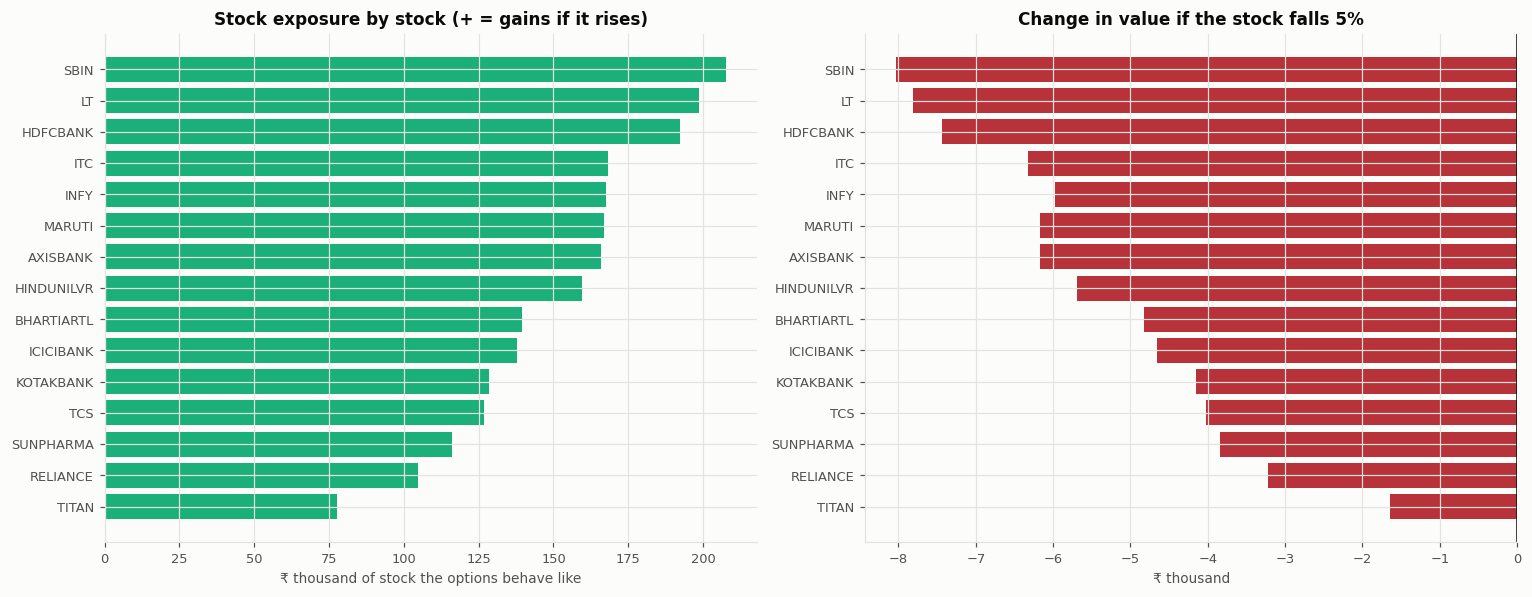

In [12]:
b = book.iloc[:-1].sort_values("Stock-equivalent exposure (₹)")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].barh(b.Underlying, b["Stock-equivalent exposure (₹)"] / 1e3, color=[GAIN if v > 0 else LOSS for v in b["Stock-equivalent exposure (₹)"]])
ax[0].axvline(0, color=INK, lw=1); ax[0].set_xlabel("₹ thousand of stock the options behave like")
ax[0].set_title("Stock exposure by stock (+ = gains if it rises)")
ax[1].barh(b.Underlying, b["If the stock falls 5% (₹, exact)"] / 1e3, color=LOSS)
ax[1].axvline(0, color=INK, lw=1); ax[1].set_xlabel("₹ thousand"); ax[1].set_title("Change in value if the stock falls 5%")
fig.tight_layout()
save_chart(fig, "04_book_risk")

## 8. What Task 1 means for Task 2 (review)
Task 2: "Predict market price using ML models and compare performance w.r.t. Black-Scholes". Before agreeing its rules, three checks on Task 1's results:
1. **Is there a pattern in the gap for ML to learn?** A flexible model (LightGBM, seed 42) predicts the % gap from the inputs, scored on options it hasn't seen (5-fold). Its R² is compared with a shuffled version (R²: share of the gap explained; 0 = nothing, negative = worse than guessing the average).
2. **How big is the gap compared with the price?** Sets what "better than BS" must mean in ₹.
3. **The flagged prices:** how many and where, for the Task 2 cleaning decision.

In [13]:
X = df.loc[big, ["Spot", "Strike", "In the money by", "Time_to_Maturity", "Volatility", "Interest_Rate", "BS price"]].assign(
    Call=df.loc[big, "Is call"].astype(int))
yv = df.loc[big, "Gap (% of BS)"].clip(-1, 1).to_numpy()                       # clip a handful of extreme cheap-option gaps
kf = KFold(5, shuffle=True, random_state=SEED)
gbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50, random_state=SEED, verbose=-1)
pred = cross_val_predict(gbm, X, yv, cv=kf)
R2_REAL = r2_score(yv, pred)
r2_null = []
for i in range(20):                                                          # 20 shuffled versions: what R² looks like with no pattern
    ys = np.random.default_rng(SEED + i).permutation(yv)
    r2_null.append(r2_score(ys, cross_val_predict(gbm, X, ys, cv=kf)))
print(f"R² of the % gap from the inputs (unseen options): {R2_REAL:+.4f}; shuffled versions: {np.mean(r2_null):+.4f} "
      f"(range {min(r2_null):+.4f} to {max(r2_null):+.4f})")
mae_if_learned = np.abs(yv - pred).mean(); mae_bs = np.abs(yv).mean()
print(f"Average |gap %|: BS alone {mae_bs:.2%}; BS + learned correction {mae_if_learned:.2%}")

review = pd.DataFrame([
    ["The gap has no direction (bias ₹%+.2f, range includes 0) and no link with any input (all |link| ≤ %.3f)" % (G["Bias (₹)"], links["Rank link with gap %"].abs().max()),
     "BS already captures everything the 5 inputs can explain", "Task 2's honest expectation: ML can match BS, unlikely to beat it by much; must be judged against BS on unseen options"],
    ["A flexible model explains R² = %+.4f of the %% gap (shuffled: %+.4f)" % (R2_REAL, np.mean(r2_null)),
     "No learnable pattern beyond BS", "The 'BS + correction' (hybrid) set-up (M8-02) is tested, but expected to add little"],
    ["MAE ₹%.2f, growing with price (₹%.2f cheapest fifth → ₹%.2f dearest)" % (G["MAE (₹)"], by_price.iloc[0]["MAE (₹)"], by_price.iloc[-1]["MAE (₹)"]),
     "Errors must be compared in ₹ and in %, by price group", "Task 2 reports MAE/RMSE in ₹ and % (≥ ₹1), overall and by price fifth, as here"],
    ["%d market prices below the no-arbitrage floor" % df["Below floor"].sum(),
     "Data errors that no model should learn", "Decide in Task 2: train without them, report with and without"],
    ["Book behaves like ₹%s of stock; −5%% in all stocks → ₹%s" % (f"{T_['Stock-equivalent exposure (₹)']:,.0f}", f"{T_['If the stock falls 5% (₹, exact)']:+,.0f}"),
     "Exposure is measurable from BS Greeks", "Task 2: decide whether ML prices change the hedge, and build the hedge"],
    ["Volatility −5 points → ₹%s, more than a 5%% stock fall" % f"{stress.iloc[2, 1]:+,.0f}",
     "Volatility is the biggest risk; shares can't hedge it", "Task 2: compare hedges that include options (vega), not only shares"],
    ["Spot and volatility differ for every option on the same stock (%d+ spots per stock)" % SPOTS_PER_STOCK,
     "The stock label is not a real single stock", "Task 2: size hedges in ₹; treat any hedge result that relies on mixing these as unreliable"],
    ["Whether NovaFin owns or wrote the options is not in the data or brief", "Every risk's sign depends on it",
     "Task 2: main view owned (M8-05); check the written book too"],
], columns=["What Task 1 found", "What it means", "Consequence for Task 2 decisions"])
display(review)

R² of the % gap from the inputs (unseen options): -0.1044; shuffled versions: -0.0204 (range -0.0260 to -0.0132)
Average |gap %|: BS alone 6.61%; BS + learned correction 6.85%


,What Task 1 found,What it means,Consequence for Task 2 decisions
0,"The gap has no direction (bias ₹+0.05, range i...",BS already captures everything the 5 inputs ca...,"Task 2's honest expectation: ML can match BS, ..."
1,A flexible model explains R² = -0.1044 of the ...,No learnable pattern beyond BS,The 'BS + correction' (hybrid) set-up (M8-02) ...
2,"MAE ₹5.84, growing with price (₹1.48 cheapest ...","Errors must be compared in ₹ and in %, by pric...","Task 2 reports MAE/RMSE in ₹ and % (≥ ₹1), ove..."
3,359 market prices below the no-arbitrage floor,Data errors that no model should learn,"Decide in Task 2: train without them, report w..."
4,"Book behaves like ₹2,257,447 of stock; −5% in ...",Exposure is measurable from BS Greeks,Task 2: decide whether ML prices change the he...
5,"Volatility −5 points → ₹-239,685, more than a ...",Volatility is the biggest risk; shares can't h...,Task 2: compare hedges that include options (v...
6,Spot and volatility differ for every option on...,The stock label is not a real single stock,Task 2: size hedges in ₹; treat any hedge resu...
7,Whether NovaFin owns or wrote the options is n...,Every risk's sign depends on it,Task 2: main view owned (M8-05); check the wri...


## 9. What the results say

**In one sentence: Black-Scholes prices these options well — the market is on average only ₹5.84 (about 3%) away, with no direction and no pattern — and its Greeks show the book behaves like ₹22.6 lakh of stock, with volatility its biggest risk.**

All figures are for one unit of each of the 10,000 options (decision M8-05).

### How close is BS to the market?

| Measure | Value | 95% range | What it means |
| --- | --- | --- | --- |
| Our BS vs the file's BS | Largest difference ₹0.27 | — | Our formula is right; differences are rounding |
| Average gap size (MAE) | **₹5.84** | ₹5.69 to ₹6.01 | How far BS is from the market per option, on average |
| Typical gap, big misses counted extra (RMSE) | ₹9.81 | ₹9.51 to ₹10.14 | Higher than MAE: a few large misses |
| Bias (average market − BS) | **₹+0.05** | ₹−0.14 to ₹+0.25 | Includes 0: BS is neither too high nor too low |
| Typical gap as % of BS (options ≥ ₹1) | **3.1%** | — | Half the options are closer than this |
| Within ±5% of BS | 69% | — | Close enough for everyday use |
| More than 20% away | 6.1% | — | Mostly options worth under ₹26, where a few rupees is a big % |

### Does the gap follow a pattern?

| Check | Result | What it means |
| --- | --- | --- |
| Direction of the gap by call/put, moneyness, maturity, volatility, price, stock | **No group differs** (all p ≥ 0.18, line 0.004) | BS is not systematically too cheap or too dear anywhere — no "volatility smile" |
| Size of the gap by group | Differs, but only because it **grows with price**: ₹1.48 for the cheapest fifth → ₹14.42 for the dearest; about 2.3–3.5% of the price except the cheapest | Market ≈ BS × (1 ± about 3% random noise) |
| Link between each input and the gap's direction | All between −0.003 and +0.017 (−1 to +1 scale) | No input predicts whether the market is above or below BS |
| A flexible model (LightGBM) predicting the gap on unseen options | R² **−0.10** (shuffled: −0.02); average |gap| 6.61% → 6.85% | Learning a correction makes it **worse**: there is nothing to learn |

### Impossible prices

| Check | Result | What it means |
| --- | --- | --- |
| Market prices below the no-arbitrage floor | **359 (3.6%)**; BS: 0 | Data errors: deep in-the-money options (mostly calls) whose random negative gap pushed them under the lowest logical price |
| Their gap vs BS | MAE ₹12.62 vs ₹5.59 for the rest | They distort error measures and must not be learned in Task 2 |

### The option book's risk (Greeks, one unit each)

| Measure | Whole book | What it means |
| --- | --- | --- |
| Value at market | **₹19.4 lakh** | 10,000 options |
| Stock-equivalent exposure (delta × spot) | **₹22.6 lakh** | The book gains and loses like ₹22.6 lakh of shares; calls add ₹55.3 lakh, puts subtract ₹32.7 lakh |
| All stocks fall 5% | **−₹0.80 lakh** | Less than 5% × ₹22.6 lakh = ₹1.13 lakh, because the options cushion falls (gamma) |
| All stocks rise 5% | **+₹1.44 lakh** | Gains more than it loses: owning options gives this one-sided shape |
| Volatility +1 point | **+₹50,463** | Jumpier markets raise the book's value |
| Each day that passes (theta) | **−₹2,068** | About ₹7.5 lakh a year if nothing else changes: the cost of holding options |
| Largest stock exposures | SBIN ₹2.08 lakh, LT ₹1.98 lakh; smallest TITAN ₹0.78 lakh | Where a hedge matters most |
| Book at BS vs at market | Net ₹+530 (0.03%); option by option ₹58,420 (3.0%) | Valuing the book with BS changes its total by almost nothing; single options can be off by ~3% |

### Data check: one price per stock? (decision M8-18)

| Check | Result | What it means |
| --- | --- | --- |
| Spot prices per stock on the one pricing day | **623–702 different spots per stock**, ₹100–₹3,500 | A real stock has one price on a day: the stock label does not tie options together |
| Volatility per stock | Hundreds of different volatilities per stock | Same |
| Effect on pricing | None | BS uses each row's own inputs |
| Effect on risk | Small (Task 2 test: stock-move risk ₹42,500 grouped by label vs ₹40,500 treating each option separately) | Risk and hedges are added up in ₹; share counts per stock are not meaningful |

### Volatility: the book's biggest risk (decision M8-19)

| Scenario (owned book) | Change in value |
| --- | --- |
| Stocks −5% | −₹79,948 |
| Stocks +5% | +₹1,43,768 |
| **Volatility −5 points (markets calm down)** | **−₹2,39,685** |
| Volatility +5 points | +₹2,61,843 |
| Stocks −5% and volatility +5 (typical sell-off) | +₹1,80,001 |
| Stocks +5% and volatility −5 (calm rally) | −₹90,075 |

**A calm market hurts this book more than a crash.** Shares can't hedge this. **If NovaFin wrote (sold) these options instead, every sign flips** — the data and brief don't say which; the main view is "owned" (M8-05), and Task 2 checks both (M8-20).

### What goes to Task 2 (the review)

| What Task 1 found | What it means | Task 2 decision it affects |
| --- | --- | --- |
| No direction, no pattern; a learned correction makes things worse | BS already explains everything the inputs can | Honest expectation: ML can at best match BS; it must be judged against BS on unseen options |
| Gap ≈ 3% of price, growing with price | Errors must be compared in ₹ and %, by price group | Task 2 uses the same measures as Task 1 |
| 359 impossible prices | Data errors | Train without them; report with and without |
| Book ≈ ₹22.6 lakh of stock; −5% → −₹0.80 lakh | Exposure is measurable now | Task 2: build the hedge |
| Volatility −5 points → −₹2.40 lakh | Biggest risk; shares can't hedge it | Task 2: compare hedges that include options |
| Spot and volatility differ for every option on a stock | Stock label isn't a real single stock | Task 2: hedges in ₹; distrust results that rely on mixing them |
| Owned or written not known | Every risk's sign depends on it | Task 2: owned as main view, written as a check |

## 10. Save the outputs
- `FINAL_M8_T1_bs_benchmark.csv`: one row per option: inputs, our BS price, market price, gap in ₹ and %, flags, Greeks, book exposure, and a plain-words explanation.
- `gap_by_segment.csv`, `segment_tests.csv`, `book_risk_by_stock.csv`, `key_numbers.json` (read by Task 2 and the workbook).

In [14]:
def why_in_words(r) -> str:
    """One plain sentence per option: what BS says, what the market pays, and what that means."""
    kind = "call (right to buy)" if r["Is call"] else "put (right to sell)"
    itm = r["In the money by"]
    where = ("at the money" if abs(itm) <= 0.02 else f"{itm:.0%} in the money" if itm > 0 else f"{-itm:.0%} out of the money")
    s = (f"{r.Underlying} {kind} at strike ₹{r.Strike:,.2f} with the stock at ₹{r.Spot:,.2f} ({where}), "
         f"{r.Time_to_Maturity:.2f} years left, volatility {r.Volatility:.0%}: Black-Scholes says ₹{r['BS price']:,.2f}, the market pays "
         f"₹{r.Market_Price:,.2f}, ")
    g = r["Gap (₹)"]
    if abs(g) < 0.005:
        s += "the same."
    else:
        pct_txt = f" ({abs(r['Gap (% of BS)']):.1%})" if pd.notna(r["Gap (% of BS)"]) else ""
        s += f"₹{abs(g):,.2f}{pct_txt} {'above' if g > 0 else 'below'} the formula."
    if r["Below floor"]:
        s += f" The market price is below the lowest logical price (₹{r['No-arbitrage floor (₹)']:,.2f}), so it is likely a data error."
    s += (f" If the stock rises ₹1 this option changes by ₹{r.Delta:+.2f}; it {'loses' if r.Theta_per_day < 0 else 'gains'} "
          f"₹{abs(r.Theta_per_day):.2f} a day as time passes.")
    return s


final = pd.DataFrame({
    "Option ID": df.Option_ID, "Stock": df.Underlying, "Type": df.Option_Type, "Strike (₹)": df.Strike, "Spot (₹)": df.Spot,
    "Expiry": df.Expiry.dt.strftime("%Y-%m-%d"), "Time to maturity (years)": df.Time_to_Maturity, "Volatility": df.Volatility,
    "Interest rate": df.Interest_Rate, "In the money by": df["In the money by"], "Moneyness band": df["Moneyness band"].astype(str),
    "BS price (₹, ours)": df["BS price"], "BS price (₹, file)": df.Black_Scholes_Price, "Market price (₹)": df.Market_Price,
    "Gap: market − BS (₹)": df["Gap (₹)"], "Gap (% of BS; options ≥ ₹1)": df["Gap (% of BS)"],
    "No-arbitrage floor (₹)": df["No-arbitrage floor (₹)"], "Market price below floor?": np.where(df["Below floor"], "Yes", "No"),
    "Delta": df.Delta, "Gamma": df.Gamma, "Vega (₹ per +1 volatility point)": df.Vega_per_vol_point, "Theta (₹ per day)": df.Theta_per_day,
    "Stock-equivalent exposure (₹)": df["Stock-equivalent exposure (₹)"], "Why, in words": df.apply(why_in_words, axis=1)})
save_table(final.round(6), "FINAL_M8_T1_bs_benchmark")
save_table(segments.round(6), "gap_by_segment")
save_table(seg_tests.round(6), "segment_tests")
save_table(book.round(2), "book_risk_by_stock")
save_table(stress.round(2), "book_stress_scenarios"); save_table(spot_check.reset_index().round(4), "spot_check_by_stock")
print("Example:", final["Why, in words"].iloc[0])


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


key = {"options": len(df), "calls": int(df["Is call"].sum()), "puts": int((~df["Is call"]).sum()), "stocks": int(df.Underlying.nunique()),
       "pricing_date": str(pricing_date.min().date()), "bs_vs_file_max_diff": r4(diff.max()),
       "mae": r4(G["MAE (₹)"]), "rmse": r4(G["RMSE (₹)"]), "bias": r4(G["Bias (₹)"]),
       "mae_range": [r4(v) for v in B["MAE (₹)"]], "rmse_range": [r4(v) for v in B["RMSE (₹)"]], "bias_range": [r4(v) for v in B["Bias (₹)"]],
       "median_abs_pct": r4(pct.abs().median()), "within_5pct": r4((pct.abs() <= 0.05).mean()), "over_20pct": r4((pct.abs() > 0.20).mean()),
       "options_under_1": int((~big).sum()), "mae_by_price_fifth": [r4(v) for v in by_price["MAE (₹)"]],
       "segment_tests_passing": int(((seg_tests["Passes the line (direction)"] == "Yes") | (seg_tests["Passes the line (size)"] == "Yes")).sum()),
       "segment_line": r4(LINE), "max_abs_input_link": r4(links["Rank link with gap %"].abs().max()),
       "below_floor": int(df["Below floor"].sum()),
       "book": {"value": r4(T_["Book value at market (₹)"]), "stock_equivalent": r4(T_["Stock-equivalent exposure (₹)"]),
                "vega": r4(T_["Vega: ₹ for volatility +1 point"]), "theta_day": r4(T_["Theta: ₹ per day"]),
                "fall5_exact": r4(T_["If the stock falls 5% (₹, exact)"]), "rise5_exact": r4(T_["If the stock rises 5% (₹, exact)"]),
                "net_gap": r4(df["Gap (₹)"].sum()), "abs_gap_total": r4(df["Gap (₹)"].abs().sum()),
                "stress": {r.Scenario: r4(r["Change in book value (₹)"]) for _, r in stress.iterrows()}},
       "spots_per_stock_min": SPOTS_PER_STOCK,
       "task2_review": {"gap_r2": r4(R2_REAL), "gap_r2_shuffled": r4(np.mean(r2_null)), "abs_pct_bs": r4(mae_bs), "abs_pct_learned": r4(mae_if_learned)}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix()); print(sorted(p.name for p in OUT_DIR.iterdir()))

Example: MARUTI put (right to sell) at strike ₹2,235.17 with the stock at ₹1,863.14 (20% in the money), 0.63 years left, volatility 20%: Black-Scholes says ₹302.61, the market pays ₹320.43, ₹17.82 (5.9%) above the formula. If the stock rises ₹1 this option changes by ₹-0.79; it gains ₹0.18 a day as time passes.
Saved to module_08_derivatives/outputs/task1
['01_eda_inputs.png', '02_market_vs_bs.png', '03_where_bs_misses.png', '04_book_risk.png', 'FINAL_M8_T1_bs_benchmark.csv', 'book_risk_by_stock.csv', 'book_stress_scenarios.csv', 'gap_by_segment.csv', 'key_numbers.json', 'segment_tests.csv', 'spot_check_by_stock.csv']
